<a href="https://colab.research.google.com/github/leon72305-source/DSAI_FINAL/blob/main/DSandAIP2027_Drafts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## *Datasets Description*

| Column | Meaning |
| ----------- | ----------- |
| `df_chargers` | Dataset for Public Charging Infrastructure Statistics |
| `df_piv` | Dataset for Licensed Plug-In Vehicles (PIVs) Statistics|
| `ONS Code` | |
| `ONS Geography` | |
| `Quarter` | |

## Environment Setup

The `-q` flag keeps the output quiet.

In [12]:
from google.colab import drive

drive.mount("/content/drive/")

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [13]:
import pandas as pd
import numpy as np

from datetime import datetime

import re

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [14]:
def section(title):
    print('\n' + '=' * 70)
    print(f'  {title}')
    print('=' * 70)

## Loading the datasets

In [15]:
#Imports datasets from dataset folder in Google Drive
folder_path = "/content/drive/MyDrive/DataSet/"

#Sets up dataframe for dataset of plugged-in vehicle statistics (PIVs) and public charging infrastructures
df_piv = pd.read_csv(folder_path + "veh0142.csv", header=4)
df_chargers = pd.read_csv(folder_path + "evci9001.csv", header=2)

#Prints out total columns and rows
print("df_piv shape:", df_piv.shape)
print("df_chargers shape:", df_chargers.shape)

#Displays datasets to ensure it is imported correctly
display(df_piv.head(3))
display(df_chargers.head(3))

df_piv shape: (26156, 74)
df_chargers shape: (470, 30)


,Units,BodyType,Fuel,Keepership,ONS Sort,ONS Code,ONS Geography,2026 Q2,2026 Q1,2025 Q4,...,2012 Q1,2011 Q4,2011 Q3,2011 Q2,2011 Q1,2010 Q4,2010 Q3,2010 Q2,2010 Q1,2009 Q4
0,Number,Buses and coaches,Battery electric,Company,1,K02000001,United Kingdom,"8,817","8,235","7,669",...,[x],[x],[x],[x],[x],[x],[x],[x],[x],[x]
1,Number,Buses and coaches,Battery electric,Company,2,K03000001,Great Britain,"8,549","7,988","7,425",...,54,58,57,59,58,49,45,41,40,38
2,Number,Buses and coaches,Battery electric,Company,3,E92000001,England,"7,333","6,804","6,276",...,51,55,54,57,55,46,43,39,38,36


,Local authority / region code,Local authority / region name,Oct-19,Jan-20,Apr-20,Jul-20,Oct-20,Jan-21,Apr-21,Jul-21,...,Apr-24,Jul-24,Oct-24 [Note 14],Jan-25,Apr-25,Jul-25,Oct-25,Jan-26,Apr-26,Jul-26
0,K02000001,United Kingdom,"15,116","16,505","17,947","18,265","19,487","20,775","22,790","24,374",...,"59,670","64,632","70,042","73,334","76,507","82,002","86,021","87,796","92,141","94,595"
1,K03000001,Great Britain,"14,821","16,210","17,642","17,953","19,169","20,455","22,463","24,044",...,"59,125","64,014","69,403","72,654","75,835","81,318","85,283","87,069","91,414","93,864"
2,E92000001,England,"12,549","13,719","14,979","15,395","16,456","17,459","19,261","20,563",...,"51,506","55,631","60,364","63,389","65,877","70,672","74,115","75,818","79,198","81,231"


## Data filtering and data quality audit

In [16]:
#Prints out current name of columns
print("df_piv columns:", df_piv.columns[:7].tolist())
print("df_chargers columns:", df_chargers.columns[:2].tolist())

df_piv columns: ['Units', 'BodyType', 'Fuel', 'Keepership', 'ONS Sort', 'ONS Code', 'ONS Geography']
df_chargers columns: ['Local authority / region code', 'Local authority / region name']


In [17]:
#Standardizes column names with same data values for both datasets
df_chargers = df_chargers.rename(columns={
    'Local authority / region code':'ONS Code' ,
    'Local authority / region name':'ONS Geography'
})
#Drops the 'Units' column in 'df_piv'
df_piv = df_piv.drop(columns=['Units'], errors='ignore')

# Keep only the rows representing Total Keepership
target_cols = ['Keepership', 'Fuel', 'BodyType']

for col in target_cols:
    if col in df_piv.columns:
        # Safely convert to string, fill blanks, and filter for 'total'
        df_piv = df_piv[df_piv[col].fillna('').astype(str).str.lower() == 'total']
        # Drop the column now that it's filtered
        df_piv = df_piv.drop(columns=[col])
    else:
        print(f"Column '{col}' not found, skipping.")

print("\nColumn titles are successfully synced!")

#Displays new dataframe shape after dropping
print(f"Cleaned df_piv shape: {df_piv.shape}")
print(f"Cleaned df_chargers shape: {df_chargers.shape}")

#Displays changes made to column title
display(df_piv.head(3))
display(df_chargers.head(3))


Column titles are successfully synced!
Cleaned df_piv shape: (447, 70)
Cleaned df_chargers shape: (470, 30)


,ONS Sort,ONS Code,ONS Geography,2026 Q2,2026 Q1,2025 Q4,2025 Q3,2025 Q2,2025 Q1,2024 Q4,...,2012 Q1,2011 Q4,2011 Q3,2011 Q2,2011 Q1,2010 Q4,2010 Q3,2010 Q2,2010 Q1,2009 Q4
25709,1,K02000001,United Kingdom,"3,226,911","2,996,785","2,786,527","2,624,664","2,429,283","2,268,199","2,094,882",...,[x],[x],[x],[x],[x],[x],[x],[x],[x],[x]
25710,2,K03000001,Great Britain,"3,173,947","2,948,245","2,741,625","2,582,243","2,390,023","2,231,797","2,061,994",...,"9,365","9,018","8,935","8,865","8,544","8,136","8,066","8,268","8,146","8,057"
25711,3,E92000001,England,"2,845,010","2,645,505","2,459,524","2,318,378","2,149,900","2,008,055","1,857,556",...,"8,454","8,274","8,218","8,066","7,876","7,595","7,533","7,696","7,634","7,560"


,ONS Code,ONS Geography,Oct-19,Jan-20,Apr-20,Jul-20,Oct-20,Jan-21,Apr-21,Jul-21,...,Apr-24,Jul-24,Oct-24 [Note 14],Jan-25,Apr-25,Jul-25,Oct-25,Jan-26,Apr-26,Jul-26
0,K02000001,United Kingdom,"15,116","16,505","17,947","18,265","19,487","20,775","22,790","24,374",...,"59,670","64,632","70,042","73,334","76,507","82,002","86,021","87,796","92,141","94,595"
1,K03000001,Great Britain,"14,821","16,210","17,642","17,953","19,169","20,455","22,463","24,044",...,"59,125","64,014","69,403","72,654","75,835","81,318","85,283","87,069","91,414","93,864"
2,E92000001,England,"12,549","13,719","14,979","15,395","16,456","17,459","19,261","20,563",...,"51,506","55,631","60,364","63,389","65,877","70,672","74,115","75,818","79,198","81,231"


In [18]:
#Classes months into its destined quartile group
quarter_map = {
    'jan': 1, 'feb': 1, 'mar': 1,
    'apr': 2, 'may': 2, 'jun': 2,
    'jul': 3, 'aug': 3, 'sep': 3,
    'oct': 4, 'nov': 4, 'dec': 4
}

#Sets up filters for 'df_piv'
def filter_piv(df):
    cols_to_keep = []
    for col in df.columns:
        #Converts column names into clean text string
        col_str = str(col).strip()
        #Scans column for time patterns
        match = re.search(r'(20\d{2})\s*Q?([1-4])?', col_str)
        if match:
            #Converts the 4-digit year into an integer
            year = int(match.group(1))
            #Extract the quartile number if present
            q_match = match.group(2)
            #Converts quartiles to integer when possible
            quarter = int(q_match) if q_match else None

            if year > 2019:
                cols_to_keep.append(col)
            #Ensures that quartiles before 2019 Q4 are dropped to synchronize dates across two datasets
            elif year == 2019:
                if quarter is None or quarter >= 4:
                    cols_to_keep.append(col)
        else:
            #Keeps non-timeline columns like ONS codes
            cols_to_keep.append(col)
    #Returns filtered dataframes
    return df[cols_to_keep]

#Sets up filters for 'df_chargers'
def filter_chargers(df):
    rename_mapping = {}
    cols_to_drop = []
    for col in df.columns:
        col_str = str(col).strip().lower()
        #Looks for first 3 letters of column title names and last 2 digits
        match = re.search(r'([a-z]{3})[-/\s]?(\d{2,4})', col_str)
        if match:
            #Grabs matched month's and years' strings
            month_str = match.group(1)
            year_str = match.group(2)

            if month_str in quarter_map:
                #Converts matched months into its quartile group
                quarter = quarter_map[month_str]
                #Converts 'year_str' from string to integer
                year = int(year_str)
                if year < 100:
                    year += 2000

                #Ensures data kept is only until Q2 2026
                if (year < 2026) or (year == 2026 and quarter <= 2):
                    #Creates new data format of "Year Q?"
                    new_col_name = f"{year} Q{quarter}"
                    rename_mapping[col] = new_col_name
                else:
                    #Groups columns to drop past Q2 2026
                    cols_to_drop.append(col)

    #Drops columns in 'cols_to_drop'
    df_filtered = df.drop(columns=cols_to_drop, errors='ignore')
    #Performs function to rename according to new data format of "Year Q?"
    df_filtered = df_filtered.rename(columns=rename_mapping)

    #Separates metadata to prevent alphabetical scrambling
    meta_cols = [c for c in df_filtered.columns if c not in rename_mapping.values()]
    time_cols = [c for c in df_filtered.columns if c in rename_mapping.values()]

    df_meta = df_filtered[meta_cols]

    #Precaution measure of grouping duplicate groups together
    df_times = df_filtered[time_cols].T.groupby(level=0).last().T

    #Returns a combined and formatted dataframe after filtering
    return pd.concat([df_meta, df_times], axis=1)

#Performs cleaning functions for both datasets
df_piv = filter_piv(df_piv)
df_chargers = filter_chargers(df_chargers)

#Displays new dataframe shape after cleaning
print(f"Cleaned df_piv shape: {df_piv.shape}")
print(f"Cleaned df_chargers shape: {df_chargers.shape}")

#Displays updated dataframe formatting
display(df_piv.head(3))
display(df_chargers.head(3))

Cleaned df_piv shape: (447, 30)
Cleaned df_chargers shape: (470, 29)


,ONS Sort,ONS Code,ONS Geography,2026 Q2,2026 Q1,2025 Q4,2025 Q3,2025 Q2,2025 Q1,2024 Q4,...,2022 Q1,2021 Q4,2021 Q3,2021 Q2,2021 Q1,2020 Q4,2020 Q3,2020 Q2,2020 Q1,2019 Q4
25709,1,K02000001,United Kingdom,"3,226,911","2,996,785","2,786,527","2,624,664","2,429,283","2,268,199","2,094,882",...,"843,287","747,951","651,383","570,613","493,228","435,604","371,873","314,253","296,209","265,120"
25710,2,K03000001,Great Britain,"3,173,947","2,948,245","2,741,625","2,582,243","2,390,023","2,231,797","2,061,994",...,"832,930","739,096","643,553","563,859","487,493","430,671","367,608","310,549","292,674","261,958"
25711,3,E92000001,England,"2,845,010","2,645,505","2,459,524","2,318,378","2,149,900","2,008,055","1,857,556",...,"756,200","668,649","581,996","510,199","440,488","389,429","332,548","280,645","266,542","236,096"


,ONS Code,ONS Geography,2019 Q4,2020 Q1,2020 Q2,2020 Q3,2020 Q4,2021 Q1,2021 Q2,2021 Q3,...,2024 Q1,2024 Q2,2024 Q3,2024 Q4,2025 Q1,2025 Q2,2025 Q3,2025 Q4,2026 Q1,2026 Q2
0,K02000001,United Kingdom,"15,116","16,505","17,947","18,265","19,487","20,775","22,790","24,374",...,"53,677","59,670","64,632","70,042","73,334","76,507","82,002","86,021","87,796","92,141"
1,K03000001,Great Britain,"14,821","16,210","17,642","17,953","19,169","20,455","22,463","24,044",...,"53,212","59,125","64,014","69,403","72,654","75,835","81,318","85,283","87,069","91,414"
2,E92000001,England,"12,549","13,719","14,979","15,395","16,456","17,459","19,261","20,563",...,"46,374","51,506","55,631","60,364","63,389","65,877","70,672","74,115","75,818","79,198"


## Data Reshaping

In [19]:
def melt_dataframe(df, value_name):
    #Drops duplicate column names
    df = df.loc[:, ~df.columns.duplicated()]

    #Scans for columns with 'Year Q?' format for melting and keeps the rest as it is
    id_vars = [col for col in df.columns if not re.match(r'^\d{4}\s+Q[1-4]$', str(col).strip())]
    value_vars = [col for col in df.columns if col not in id_vars]

    #Melt from wide to long format
    df_long = pd.melt(
        df,
        id_vars=id_vars,
        value_vars=value_vars,
        #Converts all 'Year Q?' column titles to rows under variable 'Quarter'
        var_name='Quarter',
        #Names new numeric column
        value_name=value_name
    )

    #Cleans up data values displayed
    df_long[value_name] = pd.to_numeric(
        #Ensures that data values with ',' are treated as numeric
        df_long[value_name].astype(str).str.replace(',', ''),
        #Converts missing values to NaN values
        errors='coerce'
    )
    #Returns cleaned up numerical values
    return df_long

#Performs melting functions for both datasets
df_piv_long = melt_dataframe(df_piv, 'Total EVs')
df_chargers_long = melt_dataframe(df_chargers, 'Total Chargers')

#Displays new dataframe shape after reshaping
print(f"df_piv_long shape: {df_piv_long.shape}")
print(f"df_chargers_long shape: {df_chargers_long.shape}")

#Displays updated dataframe formatting
display(df_piv_long.head(3))
display(df_chargers_long.head(3))

df_piv_long shape: (12069, 5)
df_chargers_long shape: (12690, 4)


,ONS Sort,ONS Code,ONS Geography,Quarter,Total EVs
0,1,K02000001,United Kingdom,2026 Q2,3226911
1,2,K03000001,Great Britain,2026 Q2,3173947
2,3,E92000001,England,2026 Q2,2845010


,ONS Code,ONS Geography,Quarter,Total Chargers
0,K02000001,United Kingdom,2019 Q4,15116.0
1,K03000001,Great Britain,2019 Q4,14821.0
2,E92000001,England,2019 Q4,12549.0


## Dataset Merging

In [20]:
#Combines specific columns with left join for precise match
df_core = pd.merge(
    df_piv_long,
    df_chargers_long[['ONS Code', 'Quarter', 'Total Chargers']],
    on=['ONS Code', 'Quarter'],
    #Ensures that primary vehicle records dictate the rows, keeping dataset panel intact
    how='left'
)

#Prevents data overwrite by using '_x' as primary dataframe and 'y' as incoming dataframe
if 'loc_authority_y' in df_core.columns:
    df_core = df_core.drop(columns=['loc_authority_y'])
if 'loc_authority_x' in df_core.columns:
    #Drops 'loc_authority_y' and turns 'loc_authority_x' back to its original value
    df_core = df_core.rename(columns={'loc_authority_x': 'loc_authority'})

print(f"df_core shape: {df_core.shape}")
print(f"Missing values summary:\n{df_core.isnull().sum()}")

#Displays dataframe shape after merging
print(f"df_core Shape: {df_core.shape}")

#Displays updated dataframe formatting
display(df_core.head(5))

df_core shape: (12069, 6)
Missing values summary:
ONS Sort             0
ONS Code             0
ONS Geography        0
Quarter              0
Total EVs            0
Total Chargers    1208
dtype: int64
df_core Shape: (12069, 6)


,ONS Sort,ONS Code,ONS Geography,Quarter,Total EVs,Total Chargers
0,1,K02000001,United Kingdom,2026 Q2,3226911,92141.0
1,2,K03000001,Great Britain,2026 Q2,3173947,91414.0
2,3,E92000001,England,2026 Q2,2845010,79198.0
3,4,E12000001,North East,2026 Q2,71280,2950.0
4,5,E06000047,County Durham,2026 Q2,13984,523.0


In [21]:
#Fills NaN values with a zero if regions do not have chargers installed
df_core['Total Chargers'] = df_core['Total Chargers'].fillna(0)

# Drop the temporary 'year' column if you don't need it yet
df_core = df_core.drop(columns=['year'], errors='ignore')

print(f"Remaining missing values in df_core:\n{df_core.isnull().sum()}")

#Displays dataframe shape after merging
print(f"df_core Shape: {df_core.shape}")

#Displays updated dataframe formatting
display(df_core.head(5))

Remaining missing values in df_core:
ONS Sort          0
ONS Code          0
ONS Geography     0
Quarter           0
Total EVs         0
Total Chargers    0
dtype: int64
df_core Shape: (12069, 6)


,ONS Sort,ONS Code,ONS Geography,Quarter,Total EVs,Total Chargers
0,1,K02000001,United Kingdom,2026 Q2,3226911,92141.0
1,2,K03000001,Great Britain,2026 Q2,3173947,91414.0
2,3,E92000001,England,2026 Q2,2845010,79198.0
3,4,E12000001,North East,2026 Q2,71280,2950.0
4,5,E06000047,County Durham,2026 Q2,13984,523.0


## Exploratory Data Analysis


  EXPLORATORY DATA ANALYSIS


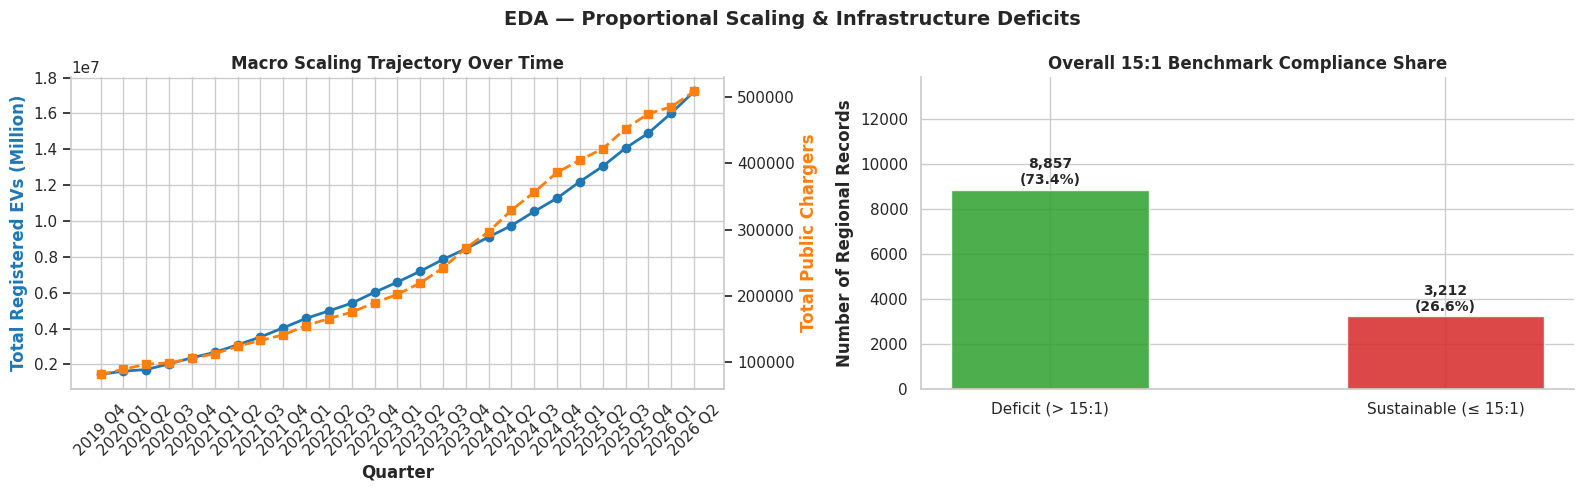

In [34]:
section('EXPLORATORY DATA ANALYSIS')

sns.set_theme(style="whitegrid")

#Chronological sorting and handles missing chargers in earlier years
df_core = df_core.sort_values(by=['ONS Code', 'Quarter'])
df_core['Total Chargers'] = df_core['Total Chargers'].fillna(0)

#Calculates EV-to-Charger ratio and deficit based of the 15:1 threshold
df_core['EV_Charger_Ratio'] = np.where(
    df_core['Total Chargers'] > 0, #Checks if region has 0 regions, which sets its value to false
    df_core['Total EVs'] / df_core['Total Chargers'], #Divides electric vehicles against chargers row-by-row
    df_core['Total EVs']
)
df_core['Deficit_Status'] = np.where(df_core['EV_Charger_Ratio'] > 15,
                                     'Deficit (> 15:1)',
                                     'Sustainable (≤ 15:1)')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('EDA — Proportional Scaling & Infrastructure Deficits', fontsize=14, fontweight='bold')

ax1 = axes[0]
quarterly_totals = df_core.groupby('Quarter')[['Total EVs', 'Total Chargers']].sum().reset_index()

ax1.plot(quarterly_totals['Quarter'], quarterly_totals['Total EVs'], label='Total EVs (Sum)', color='#1f77b4', marker='o', linewidth=2)
ax1.set_title('Macro Scaling Trajectory Over Time', fontweight='bold')
ax1.set_ylabel('Total Registered EVs (Million)', color='#1f77b4', fontweight='bold')
ax1.set_xlabel('Quarter', fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
[ax1.spines[s].set_visible(False) for s in ['top', 'right']]

ax2 = ax1.twinx()
ax2.plot(quarterly_totals['Quarter'], quarterly_totals['Total Chargers'], label='Total Chargers (Sum)', color='#ff7f0e', marker='s', linewidth=2, linestyle='--')
ax2.set_ylabel('Total Public Chargers', color='#ff7f0e', fontweight='bold')
ax2.grid(False) # Prevent gridline clashing
[ax2.spines[s].set_visible(False) for s in ['top', 'left']]

ax3 = axes[1]
status_counts = df_core['Deficit_Status'].value_counts()

bars = ax3.bar(status_counts.index, status_counts.values, color=['#2ca02c', '#d62728'], alpha=0.85, edgecolor='white', width=0.5)
total_records = len(df_core)

for bar in bars:
    height = bar.get_height()
    percentage = (height / total_records) * 100
    ax3.text(bar.get_x() + bar.get_width()/2, height + (total_records * 0.01),
            f'{height:,}\n({percentage:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax3.set_title('Overall 15:1 Benchmark Compliance Share', fontweight='bold')
ax3.set_ylabel('Number of Regional Records', fontweight='bold')
ax3.set_ylim(0, total_records * 1.15) # Leave room for text labels
[ax3.spines[s].set_visible(False) for s in ['top', 'right']]

plt.tight_layout()
plt.show()

## Feature Engineering

In [23]:
section('BASE MODEL TRAINING (80/20 split)')




  BASE MODEL TRAINING (80/20 split)
